# Healthcare KPI Data Pipeline

**Author:** Oluwatoyin Olawale Akadiri · [oluwatoyinakadiri.com](https://oluwatoyinakadiri.com)

**Goal:** Turn messy clinic exports into trustworthy weekly KPIs: appointment volume, no-show rate, claim denial rate, collections, and days to payment.

> **All data in this project is synthetic.** It is generated by `src/generate_synthetic_data.py`. No real patients, clinics, or payers are represented.

**Pipeline:** raw CSVs → Python cleaning (`src/etl.py`) → validation checks → SQLite tables → SQL KPI views (`sql/kpi_views.sql`) → weekly KPI table and charts.

In [1]:
import sys, sqlite3
sys.path.insert(0, "../src")
import pandas as pd
import matplotlib.pyplot as plt
from etl import run

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
TEAL, BLUE, ORANGE, GREY = "#0f766e", "#365bd6", "#c2410c", "#94a3b8"

## 1. What the raw exports look like

In [2]:
raw_appts = pd.read_csv("../data/raw/appointments_raw.csv")
raw_claims = pd.read_csv("../data/raw/claims_raw.csv")
print("Clinic name variants:", sorted(raw_appts["clinic"].unique()))
print("Date formats:", raw_appts["appointment_date"].head(6).tolist())
print("Amount formats:", raw_claims["billed_amount"].head(4).tolist())
raw_appts.head()

Clinic name variants: ['Downtown Clinic', 'NORTH CLINIC ', 'North Clinic', 'Riverside', 'Riverside Clinic', 'Riverside clinic', 'downtown clinic', 'north clinic']
Date formats: ['2026-05-26', '2026-05-23', '2026-06-26', '17-Apr-2026', '03-Mar-2026', '01/13/2026']
Amount formats: ['303.56', '69.99', '$80.53', '93.5']


,appointment_id,patient_id,clinic,booked_date,appointment_date,status
0,A200000,P10954,NORTH CLINIC,05/20/2026,2026-05-26,No-show
1,A200001,P10366,Riverside clinic,07-May-2026,2026-05-23,Completed
2,A200002,P12970,Riverside clinic,06/07/2026,2026-06-26,No-show
3,A200003,P10708,north clinic,04/09/2026,17-Apr-2026,Completed
4,A200004,P10059,North Clinic,02/26/2026,03-Mar-2026,NaN


Three date formats, eight spellings of three clinics, currency symbols stored as text, duplicates, and missing statuses: typical of real exports, and enough to make KPIs wrong if loaded as-is.

## 2. Run the ETL and review the cleaning log

In [3]:
con = run("../data/raw")
pd.read_sql("SELECT * FROM etl_log", con)

,metric,value
0,appointments_raw_rows,6060
1,appointments_duplicates_removed,60
2,appointments_booked_after_visit,15
3,appointments_missing_status,114
4,appointments_unmapped_clinic,0
5,appointments_clean_rows,5872
6,claims_raw_rows,4688
7,claims_nonpositive_amount,10
8,claims_orphaned,9
9,claims_clean_rows,4669


## 3. Validation checks
The pipeline stops with an error if any check fails, so a dashboard never shows numbers built on bad data.

In [4]:
pd.read_sql('SELECT * FROM validation_checks', con)

,check,passed
0,appointment_id is unique,1
1,claim_id is unique,1
2,no missing appointment dates,1
3,lead_days is never negative,1
4,status uses allowed values,1
5,billed amounts are positive,1
6,every claim links to an appointment,1
7,paid claims have days_to_payment,1


## 4. Weekly KPIs (`weekly_kpis` view)

In [5]:
weekly = pd.read_sql("SELECT * FROM weekly_kpis", con, parse_dates=["week_start"])
weekly.tail(8)

,week_start,scheduled,completed,no_show_rate_pct,avg_lead_days,claims,denial_rate_pct,collected_usd,avg_days_to_payment
18,2026-05-11,230,188,14.3,12.4,188,12.8,29598.34,26.6
19,2026-05-18,228,185,14.5,12.3,184,7.6,31848.21,28.1
20,2026-05-25,216,171,15.7,12.4,169,10.1,28500.14,30.0
21,2026-06-01,220,169,19.5,11.6,169,8.3,28712.44,29.2
22,2026-06-08,239,190,15.1,12.0,190,9.5,29682.20,25.0
23,2026-06-15,231,180,18.6,11.3,180,6.1,28442.44,28.8
24,2026-06-22,235,179,18.3,12.3,179,8.9,30164.31,27.7
25,2026-06-29,244,202,13.5,11.7,202,8.4,32679.59,25.8


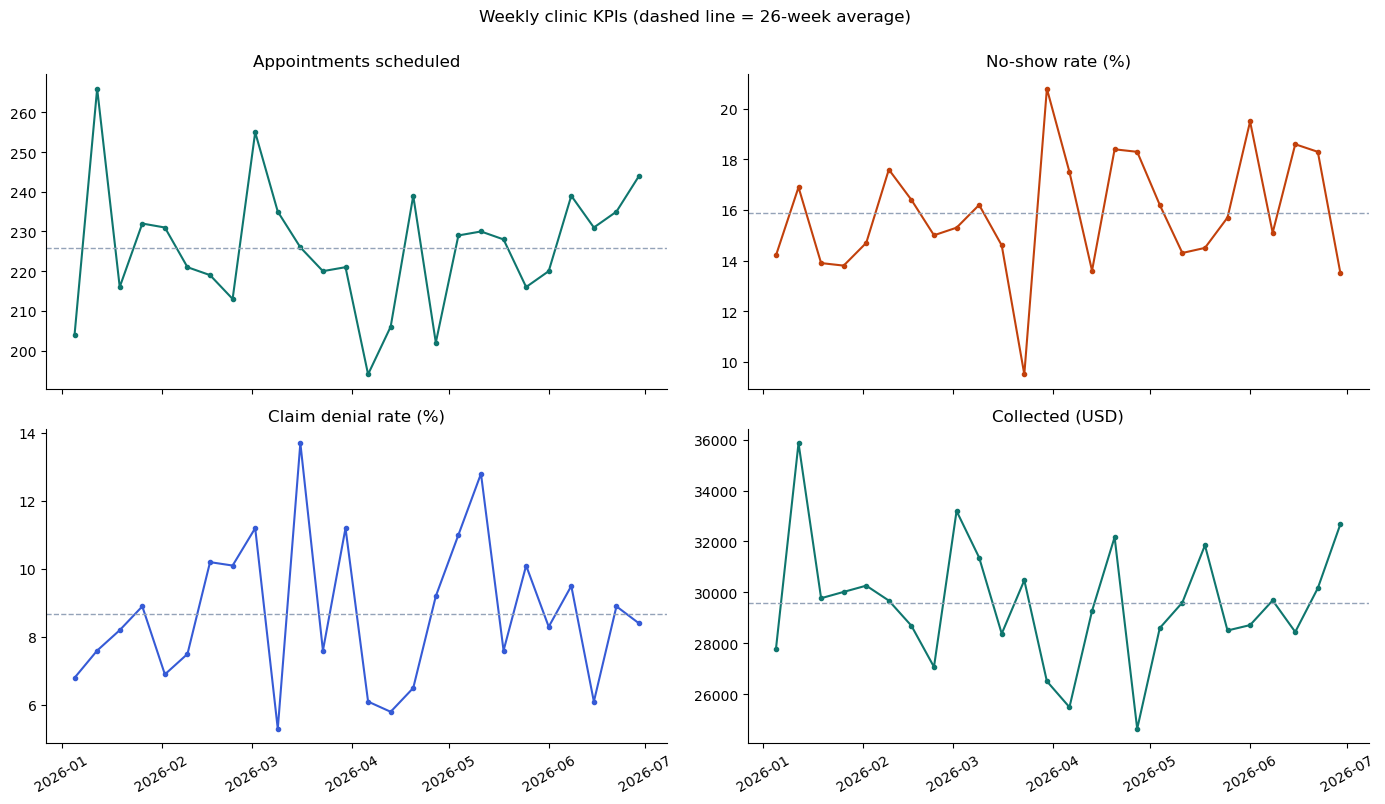

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
panels = [("scheduled", "Appointments scheduled", TEAL), ("no_show_rate_pct", "No-show rate (%)", ORANGE),
          ("denial_rate_pct", "Claim denial rate (%)", BLUE), ("collected_usd", "Collected (USD)", TEAL)]
for ax, (col, title, color) in zip(axes.flat, panels):
    ax.plot(weekly["week_start"], weekly[col], marker="o", ms=3, color=color)
    ax.axhline(weekly[col].mean(), color=GREY, ls="--", lw=1)
    ax.set_title(title); ax.tick_params(axis="x", rotation=30)
fig.suptitle("Weekly clinic KPIs (dashed line = 26-week average)", y=1.0)
plt.tight_layout(); plt.savefig("../images/weekly_kpis.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Where to act: clinics and payers

In [7]:
pd.read_sql('SELECT * FROM clinic_kpis', con)

,clinic,scheduled,no_show_rate_pct,avg_lead_days,denial_rate_pct
0,Downtown Clinic,1408,19.2,12.1,8.6
1,Riverside Clinic,2070,15.1,12.0,8.8
2,North Clinic,2394,14.6,11.8,8.6


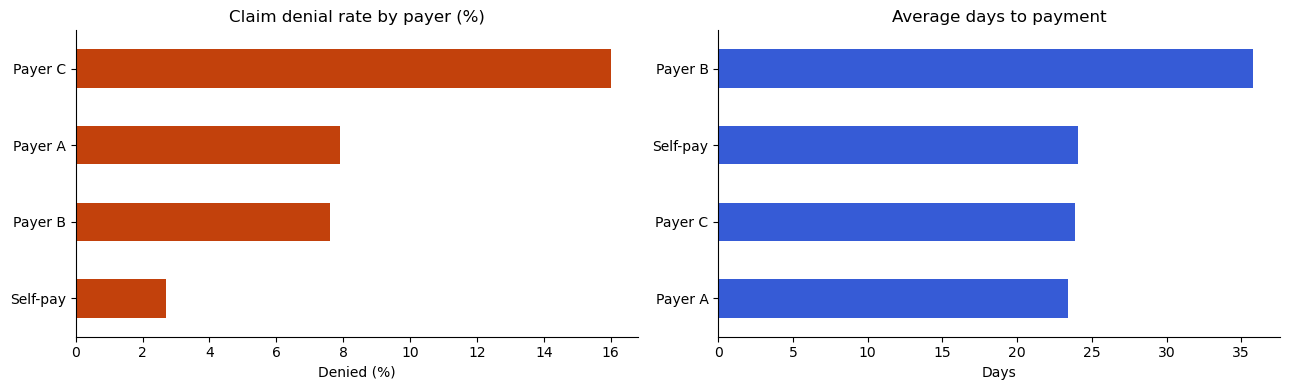

,payer,claims,denial_rate_pct,avg_days_to_payment,collected_usd
0,Payer C,961,16.0,23.9,142700.29
1,Payer A,1613,7.9,23.4,273411.85
2,Payer B,1399,7.6,35.8,231731.39
3,Self-pay,696,2.7,24.1,120964.53


In [8]:
payers = pd.read_sql("SELECT * FROM payer_kpis", con)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
payers.set_index("payer")["denial_rate_pct"].sort_values().plot.barh(ax=axes[0], color=ORANGE)
axes[0].set(title="Claim denial rate by payer (%)", xlabel="Denied (%)", ylabel="")
payers.set_index("payer")["avg_days_to_payment"].sort_values().plot.barh(ax=axes[1], color=BLUE)
axes[1].set(title="Average days to payment", xlabel="Days", ylabel="")
plt.tight_layout(); plt.savefig("../images/payer_kpis.png", dpi=150, bbox_inches="tight"); plt.show()
payers

In [9]:
lead = pd.read_sql('''
    SELECT CASE WHEN lead_days <= 3 THEN '0-3 days' WHEN lead_days <= 14 THEN '4-14 days'
                WHEN lead_days <= 30 THEN '15-30 days' ELSE '30+ days' END AS lead_band,
           MIN(lead_days) AS sort_key,
           COUNT(*) AS appointments,
           ROUND(100.0 * SUM(status = 'No-show') / COUNT(*), 1) AS no_show_rate_pct
    FROM appointments GROUP BY lead_band ORDER BY sort_key
''', con).drop(columns="sort_key")
lead

,lead_band,appointments,no_show_rate_pct
0,0-3 days,1484,9.3
1,4-14 days,2648,13.9
2,15-30 days,1271,20.5
3,30+ days,469,35.6


## 6. Takeaways
- **Cleaning changes the numbers.** Duplicates, missing statuses, impossible dates, and negative amounts were removed and logged before any KPI was calculated, with every removal counted in `etl_log`.
- **No-shows rise with booking lead time** and are highest at Downtown Clinic, so reminder calls for long-lead bookings there are the first lever.
- **Denials concentrate in one payer** (Payer C), and Payer B pays slowest, pointing billing follow-up to two specific payers rather than the whole book.

**Limitations.** The data is synthetic and the patterns were built into the generator, so the findings demonstrate the method, not real clinic behavior. A production version would load from a database or API on a schedule and feed a BI dashboard (for example Power BI) from the KPI views.